# 60 · 학습한 환경모델과 MPC

📎 **이번 질문** · 다음 상태와 보상을 예측할 수 있으면 여러 행동 계획을 미리 시험할 수 있을까요?

준비물: 27 표본평균, 52 Bellman·계획, [59 연속 제어](59_continuous_control.ipynb), 03·04 MLP·Adam. NumPy·CPU float64만 사용하며 다른 노트북 실행 상태나 다운로드에 의존하지 않습니다. 원점으로 되돌아오는 비선형 장치의 합성 제어 환경로 수식부터 실제 학습까지 연결합니다.

| 표시 | 뜻 | 읽는 법 |
|---|---|---|
| 🔑 | 핵심 | 축과 기울기 경로를 씁니다 |
| 🔍 | 확인 | 그림·손계산·독립 평가를 대조합니다 |
| 📎 | 참고 | 처음 나온 용어·관용구를 풀이합니다 |
| ✏️ | 연습 | 한두 줄을 채우고 검사합니다 |

**이 노트북에서 반드시 가져갈 세 가지**

1. 전이·보상 모델을 실제 관측 전이에서 학습하고 독립 one-step 오차를 확인합니다.
2. shooting은 후보 행동열을 비교하며 MPC는 첫 행동만 실행한 뒤 새 상태에서 다시 계획합니다.
3. 모델 오차·후보 탐색 예산·계획 길이를 구분하고 실제 환경 보상으로 평가합니다.

[학습 경로](../../docs/CURRICULUM.md) · [그림 보조 코드](../../src/utils/model_based_plots.py)

In [1]:
# 준비 셀: 그림과 독립 미분 검산 도구입니다.
import sys
from pathlib import Path
import numpy as np
project_root = next(p for p in (Path.cwd(),*Path.cwd().parents) if (p/'src/utils/plotting.py').is_file())
if str(project_root) not in sys.path:
    sys.path.insert(0,str(project_root))
from src.utils import setup_plots,run_check
from src.utils.gradcheck import numerical_gradient,rel_error
from src.utils.model_based_plots import plot_panels,plot_curves,plot_trajectories
setup_plots()

from time import perf_counter

## 🔑 1. 환경을 아는 것과 모델로 예측하는 것은 다릅니다

**이 절에서 가져갈 것:** 모델이 맞혀야 하는 관측 단위와 참 환경의 역할을 분리합니다.

59번의 원점 제어에 작은 비선형항을 더합니다. 이번에는 모델 오차와 계획을 명확히 보기 위해 환경 잡음을 없앱니다.
$$s'=.85s+.5a+.08\sin(3s),\qquad r=-(s'^2+.05a^2),\qquad a\in[-1,1].$$

> **용어**
> - **전이 모델(dynamics model)**은 상태·행동에서 다음 상태를 예측합니다.
> - **보상 모델(reward model)**은 상태·행동에서 얻을 보상을 예측합니다.
> - **모델 기반 계획**은 이 두 예측으로 미래 행동열의 보상을 비교하는 것입니다.
> - **oracle 모델**은 여기서 참 환경 식을 아는 비교용 모델입니다. 학습 모델이 아닙니다.

자료 입력 X:(N,2)는 `[s,a]`, 정답 Y:(N,2)는 `[s′,r]`입니다. 실제 환경 함수는 자료 수집과 최종 실행에 씁니다. 학습 모델을 사용하는 계획에서는 이 함수를 읽지 않고 MLP 출력만 사용합니다. oracle 계획은 별도 대조로 표시합니다.

In [2]:
example_s=np.array([[-1.],[0.],[1.]])
example_a=np.array([[.5],[0.],[-.5]])
example_next=.85*example_s+.5*example_a+.08*np.sin(3*example_s)
example_r=-(example_next**2+.05*example_a**2)
example_input=np.concatenate([example_s,example_a],axis=1)
example_target=np.concatenate([example_next,example_r],axis=1)

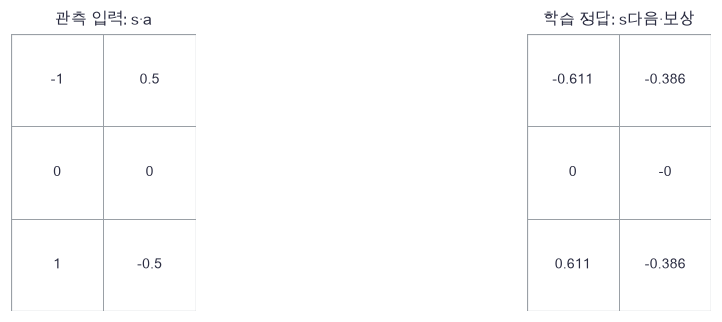

In [3]:
plot_panels([example_input,example_target],['관측 입력: s·a','학습 정답: s다음·보상'])

🔍 **확인** · 이 예제는 정확한 식을 알지만, 학습 모델은 관측된 입출력 쌍으로 파라미터를 맞춥니다. 식을 아는 oracle 계획과 학습 계획을 비교해야 모델 오차를 분리할 수 있습니다.

In [4]:
def true_step(S,A):
    """60번의 정확한 결정론 환경. 전이의 작은 비선형항과 행동 비용을 포함합니다."""
    next_s=.85*S+.5*A+.08*np.sin(3*S)
    reward=-(next_s**2+.05*A**2)
    return next_s,reward

In [5]:
def make_transitions(n,seed):
    """균일 상태·행동에서 독립 전이를 수집합니다. X:[s,a], Y:[s′,r]."""
    rng=np.random.default_rng(seed)
    S=rng.uniform(-1.5,1.5,(n,1))
    A=rng.uniform(-1.,1.,(n,1))
    next_s,reward=true_step(S,A)
    return np.concatenate([S,A],axis=1),np.concatenate([next_s,reward],axis=1)

In [6]:
# 쓰는 것: example_a (1절) · example_next (1절) · example_r (1절) · example_s (1절)
manual_next=[]
manual_reward=[]
for s,a in zip(example_s[:,0],example_a[:,0]):
    ns,r=true_step(s,a)
    manual_next.append(ns)
    manual_reward.append(r)
np.testing.assert_allclose(manual_next,example_next[:,0])  # 검산: 반복문 = 벡터화 전이
np.testing.assert_allclose(manual_reward,example_r[:,0])  # 검산: 반복문 = 벡터화 보상
np.testing.assert_allclose(true_step(np.array([[0.]]),np.array([[0.]])),np.zeros((2,1,1)))  # 검산: 원점·무행동은 그대로0
print('참 환경의 한 step 검산을 통과했습니다.')

참 환경의 한 step 검산을 통과했습니다.


### ✏️ 연습 1 · 상태 오차와 행동 비용

연습은 코딩 테스트처럼 **함수 뼈대가 미리 있고 핵심 한두 줄만 비어 있습니다.** `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓴 뒤, 셀을 실행하고 바로 아래 검사 셀을 실행하세요. 아직 채우지 않았으면 안내문만 나오고, 값이 다르면 "손계산과 다릅니다"가 나옵니다. 막히면 그 아래 "정답 보기"를 펼칩니다.

다음 상태와 행동에서 환경 보상을 계산하세요.

In [7]:
def exercise_reward_cost(next_s,action):
    """다음 상태와 행동에서 환경 보상을 계산하세요."""

    ### 구현할 내용: 다음 상태와 행동에서 환경 보상을 계산하세요.
    raise NotImplementedError
    return reward

In [8]:
def check_reward_cost(candidate):
    """작은 독립 기준값과 비교합니다."""
    np.testing.assert_allclose(candidate(np.array([0.,1.]),np.array([1.,0.])),[-.05,-1.])  # 검산: 힘만쓴비용과상태비용
    print("연습 1: 독립 기준값과 일치합니다.")

run_check(check_reward_cost,exercise_reward_cost,hint="다음 상태와 행동에서 환경 보상을 계산하세요.")

☐ exercise_reward_cost: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: 다음 상태와 행동에서 환경 보상을 계산하세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
reward = -(next_s**2+.05*action**2)
```

</details>

## 🔑 2. 다음 상태와 보상을 실제로 학습합니다

**이 절에서 가져갈 것:** 고정 전이 자료로 모델 전체를 미분하고 학습·평가를 분리합니다.

시뮬레이터를 임의의 상태로 reset할 수 있다고 가정합니다. s를[−1.5,1.5], a를[−1,1]에서 독립 균일 추출한 전이를 만듭니다. 실제 시스템에서는 이런 범위를 안전하게 수집할 수 있는지 별도로 판단해야 하지만 이 예제는 합성 시뮬레이터만 사용합니다.

모델은2→16→2 tanh MLP입니다. $H=\tanh(XW+b)$, $\hat Y=HV+c$. 손실은 $L=\frac1{2ND}\sum(\hat Y-Y)^2$, D=2이고 $G=(\hat Y-Y)/(ND)$입니다. 두 출력 좌표에 같은 가중치를 주는 이 선택은 상태·보상의 단위에 의존합니다. 검증에서는 좌표별 MSE를 따로 봅니다.

$dV=H^TG$, $dc=\sum G$, $dU=(GV^T)\odot(1-H^2)$, $dW=X^TdU$, $db=\sum dU$, $dX=dUW^T$입니다. 입력 수치미분에서는 Y를 고정합니다. 원래 환경 식으로 Y를 다시 만들면 다른 목적의 미분입니다.

고정 계획: train1024/valid256/test512(seed6001/6002/6003), 초기6000, batch난수6004,1200갱신·batch128·Adam lr.005. Adam은.9/.999 모멘트와 bias 보정·epsilon1e−8을 씁니다. validation은 관찰만 하고 조기종료나 모델선택에 쓰지 않습니다. test 확인 후 구조·스텝을 바꾸지 않습니다.

> **코드** · `integers`는 배치 복원추출입니다. 사전의 `.copy()`는 초기 모델을 보존합니다. `mean(axis=0)`은 두 출력 좌표 각각의 오차를 관측 평균합니다.

In [9]:
# 쓰는 것: true_step (1절)
learning_example=np.array([[-.8,.4],[.3,-.2],[1.,-.5]])
learning_hidden=np.tanh(learning_example@np.array([[.2,-.1],[.1,.3]]))
learning_prediction=learning_hidden@np.array([[.5,-.2],[-.1,.3]])
ns,rr=true_step(learning_example[:,:1],learning_example[:,1:2])
learning_target=np.concatenate([ns,rr],axis=1)

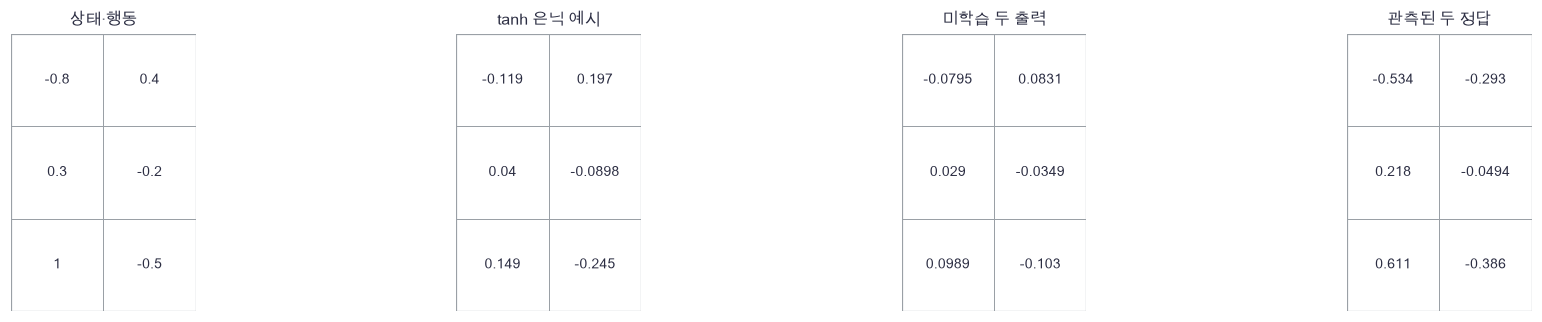

In [10]:
plot_panels([learning_example,learning_hidden,learning_prediction,learning_target],['상태·행동','tanh 은닉 예시','미학습 두 출력','관측된 두 정답'])

🔍 **확인** · 같은 모델이 전이와 보상을 함께 예측하지만 두 출력의 의미는 다릅니다. 예시 가중치의 숫자는 아래 실제 학습 초기값과 별개인 작은 직접 계산입니다.

In [11]:
def init_mlp(din,dout,seed,hidden=8):
    """tanh 은닉층 하나와 선형 출력층의 모든 배열을 초기화합니다."""
    rng=np.random.default_rng(seed)
    return {'W':rng.normal(0,.3,(din,hidden)),'b':np.zeros(hidden),
            'V':rng.normal(0,.15,(hidden,dout)),'c':np.zeros(dout)}

In [12]:
def mlp_forward(X,p):
    """H=tanh(XW+b), Y=HV+c. 입력:(N,D) → 출력:(N,K),cache."""
    H=np.tanh(X@p['W']+p['b'])
    return H@p['V']+p['c'],(X,H)

In [13]:
def mlp_backward(G,cache,p):
    """모든 파라미터·입력의 연쇄법칙입니다. G는 출력과 같은 shape입니다."""
    X,H=cache
    dU=(G@p['V'].T)*(1-H**2)
    grads={'V':H.T@G,'c':G.sum(axis=0),'W':X.T@dU,'b':dU.sum(axis=0)}
    return grads,dU@p['W'].T

In [14]:
def model_loss(X,target,p):
    """다음 상태·보상의 2좌표 반 MSE. 모든 파라미터와 입력 미분을 반환합니다."""
    prediction,cache=mlp_forward(X,p)
    residual=prediction-target
    grads,dX=mlp_backward(residual/residual.size,cache,p)
    return .5*np.mean(residual**2),grads,dX

In [15]:
def adam_step(p,g,m,v,step,lr=.001):
    """Adam .9/.999 모멘트와 bias 보정으로 배열을 갱신합니다."""
    for key in p:
        m[key]=.9*m[key]+.1*g[key]
        v[key]=.999*v[key]+.001*g[key]**2
        p[key]-=lr*(m[key]/(1-.9**step))/(np.sqrt(v[key]/(1-.999**step))+1e-8)

In [16]:
def copy_parameters(p):
    """각 배열의 독립 사본을 만듭니다."""
    return {key:value.copy() for key,value in p.items()}

In [17]:
def zero_state(p):
    """파라미터와 같은 shape의 optimizer0 상태를 만듭니다."""
    return {key:np.zeros_like(value) for key,value in p.items()}

In [18]:
def train_model(X,Y,valid_X,valid_Y,initial):
    """실제 전이 자료로82파라미터 모델을1200회 Adam 학습합니다."""
    # 쓰는 것: mlp_forward (2절) · model_loss (2절)
    p=copy_parameters(initial)
    m,v=zero_state(p),zero_state(p)
    rng=np.random.default_rng(6004)
    history=[]
    for step in range(1,1201):
        idx=rng.integers(0,len(X),128)
        loss,grads,_=model_loss(X[idx],Y[idx],p)
        adam_step(p,grads,m,v,step,lr=.005)
        if step%100==0:
            prediction,_=mlp_forward(valid_X,p)
            error=((prediction-valid_Y)**2).mean(axis=0)
            history.append([step,*error])
    return p,np.array(history)

In [19]:
# 쓰는 것: init_mlp (2절) · model_loss (2절)
probe=init_mlp(2,2,6007,3)
probe_x=np.array([[-.4,.2],[.7,-.1]])
probe_y=np.array([[.1,-.2],[.3,-.1]])
_,analytic,analytic_x=model_loss(probe_x,probe_y,probe)

In [20]:
def model_objective():
    """고정 관측 정답에서 모델 전체를 중심차분합니다."""
    # 쓰는 것: model_loss (2절)
    return model_loss(probe_x,probe_y,probe)[0]

In [21]:
errors=[]
for key in probe:
    numeric=numerical_gradient(model_objective,probe[key])
    np.testing.assert_allclose(analytic[key],numeric,atol=2e-8)  # 검산: 두 출력 모델의 모든 파라미터
    errors.append(np.max(np.abs(analytic[key]-numeric)))
np.testing.assert_allclose(analytic_x,numerical_gradient(model_objective,probe_x),atol=2e-8)  # 검산: 상태·행동 입력 전체
print('전체 모델 미분 최대 절대오차',max(errors))

전체 모델 미분 최대 절대오차 3.3953811984233084e-12


In [22]:
# 쓰는 것: init_mlp (2절) · make_transitions (1절) · mlp_forward (2절) · train_model (2절)
train_x,train_y=make_transitions(1024,6001)
valid_x,valid_y=make_transitions(256,6002)
test_x,test_y=make_transitions(512,6003)
initial=init_mlp(2,2,6000,16)
fitted,history=train_model(train_x,train_y,valid_x,valid_y,initial)
test_prediction,_=mlp_forward(test_x,fitted)
test_mse=((test_prediction-test_y)**2).mean(axis=0)
print('학습 파라미터',sum(a.size for a in fitted.values()),'· test [다음상태MSE, 보상MSE]',test_mse)
np.testing.assert_array_equal(initial['W'],init_mlp(2,2,6000,16)['W'])  # 검산: 초기 사본 보존

학습 파라미터 82 · test [다음상태MSE, 보상MSE] [0.00019005 0.00327866]


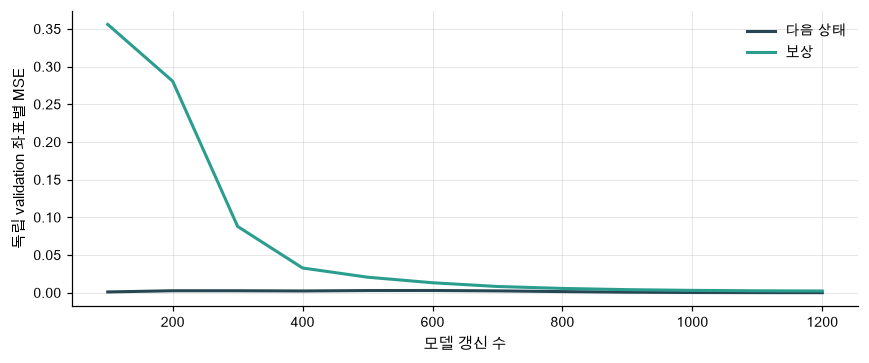

In [23]:
plot_curves([history[:,[0,1]],history[:,[0,2]]],['다음 상태','보상'],'독립 validation 좌표별 MSE')

### ✏️ 연습 2 · 두 좌표의 손실 미분

반 MSE의 두 출력 미분을 관측·출력 좌표 모두로 평균하세요.

In [24]:
def exercise_two_outputs(prediction,target):
    """반 MSE의 두 출력 미분을 관측·출력 좌표 모두로 평균하세요."""

    ### 구현할 내용: 반 MSE의 두 출력 미분을 관측·출력 좌표 모두로 평균하세요.
    raise NotImplementedError
    return G

In [25]:
def check_two_outputs(candidate):
    """작은 독립 기준값과 비교합니다."""
    np.testing.assert_allclose(candidate(np.ones((2,2)),np.zeros((2,2))),np.full((2,2),.25))  # 검산: N×D=4
    print("연습 2: 독립 기준값과 일치합니다.")

run_check(check_two_outputs,exercise_two_outputs,hint="반 MSE의 두 출력 미분을 관측·출력 좌표 모두로 평균하세요.")

☐ exercise_two_outputs: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: 반 MSE의 두 출력 미분을 관측·출력 좌표 모두로 평균하세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
G = (prediction-target)/prediction.size
```

</details>

## 🔑 3. 후보 행동열을 모델 안에서 펼칩니다

**이 절에서 가져갈 것:** shooting은 같은 시작 상태에서 여러 행동열의 예측 반환을 비교합니다.

지금 상태에서 힘을 세 번 어떻게 줄지 후보를 여러 개 만듭니다. 각 후보를 모델에서 끝까지 실행한 것처럼 계산하고 할인 보상이 가장 큰 후보를 고릅니다.

> **용어** · **rollout**은 전이를 반복 적용해 미래 경로를 펼치는 것입니다. **random shooting**은 무작위 후보 행동열을 만들어 점수를 비교하는 계획 방법입니다. **open-loop 계획**은 중간의 실제 관측 없이 미리 정한 행동열을 끝까지 쓰는 계획입니다.

행동열 $A:(N,K,H)$의 축은 시작상태·후보·계획길이입니다. $\hat s_{h+1}=f_\phi(\hat s_h,a_h)$, $\hat G=\sum_{h=0}^{H-1}.95^h\hat r_\phi(\hat s_h,a_h)$로 후보별 반환을 구합니다. 처음 상태는 K번 복제하고 NK개 전이를 한 번에 계산합니다. **이 계획은 미분하지 않는 후보 탐색**입니다. 학습된 모델의 backward와 구분합니다. K개 후보 중 최선이지 연속 행동 전체의 최적해라는 보장은 없습니다.

> **코드** · `repeat(S,K,axis=0)`는 시작상태마다 후보 K개를 붙입니다. `reshape(N*K,1)`로 같은 시각의 후보 행동을 모델에 넣습니다. `argmax(axis=1)`은 시작상태마다 최고 후보를 고릅니다.

In [26]:
# 쓰는 것: fitted (2절) · mlp_forward (2절)
candidate_actions=np.array([[[-1.,0.],[0.,0.],[1.,-1.]]])
candidate_start=np.array([[.8]])
candidate_scores=[]
candidate_paths=[]
for sequence in candidate_actions[0]:
    state=candidate_start.copy()
    total=0.
    path=[float(state[0,0])]
    for t,action in enumerate(sequence):
        output,_=mlp_forward(np.concatenate([state,np.array([[action]])],axis=1),fitted)
        state=output[:,:1]
        total+=.95**t*float(output[0,1])
        path.append(float(state[0,0]))
    candidate_scores.append(total)
    candidate_paths.append(path)

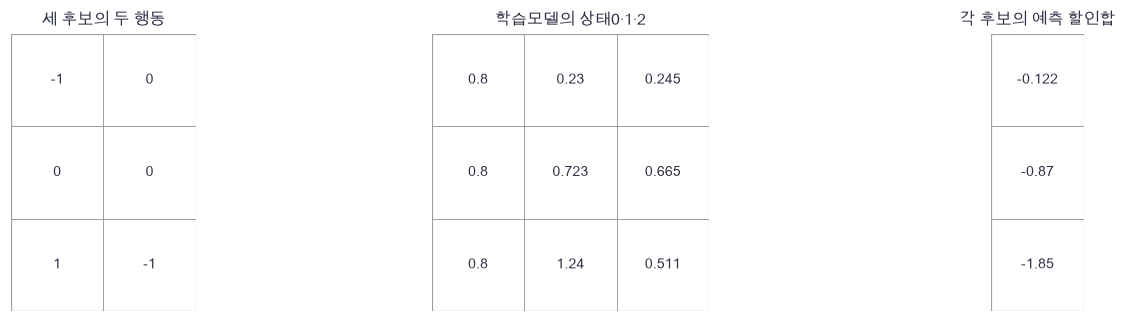

In [27]:
plot_panels([candidate_actions[0],np.array(candidate_paths),np.array(candidate_scores)[:,None]],['세 후보의 두 행동','학습모델의 상태0·1·2','각 후보의 예측 할인합'])

🔍 **확인** · 각 행은 같은 시작상태에서 출발합니다. 낮은 상태 예측 오차만으로 보상 예측 순서가 정확하다고 보장할 수는 없습니다.

In [28]:
def predict_step(S,A,p,oracle=False):
    """계획용 한 step. oracle만 참 환경을 읽으며 학습 모델은 MLP 출력만 사용합니다."""
    # 쓰는 것: mlp_forward (2절) · true_step (1절)
    if oracle:
        return true_step(S,A)
    Y,_=mlp_forward(np.concatenate([S,A],axis=1),p)
    return Y[:,:1],Y[:,1:2]

In [29]:
def rollout_sequences(S,sequences,p,oracle=False,gamma=.95):
    """후보별 open-loop 전이를 벡터화합니다. sequences:(N,K,H), scores:(N,K)."""
    n,k,horizon=sequences.shape
    state=np.repeat(S,k,axis=0)
    scores=np.zeros((n*k,1))
    states=[state.reshape(n,k).copy()]
    for time in range(horizon):
        action=sequences[:,:,time].reshape(n*k,1)
        state,reward=predict_step(state,action,p,oracle)
        scores+=gamma**time*reward
        states.append(state.reshape(n,k).copy())
    return scores.reshape(n,k),np.stack(states,axis=-1)

In [30]:
def shooting_action(S,sequences,p,oracle=False):
    """후보 전체 반환을 비교해 최고 후보의 첫 행동만 고릅니다."""
    assert sequences.shape[1]>=1, '후보가 최소1개 있어야 합니다'
    assert sequences.shape[2]>=1, '계획 길이가 최소1이어야 합니다'
    scores,paths=rollout_sequences(S,sequences,p,oracle)
    best=scores.argmax(axis=1)
    chosen=sequences[np.arange(len(S)),best]
    path=paths[np.arange(len(S)),best]
    return chosen[:,:1],chosen,path,scores[np.arange(len(S)),best]

In [31]:
# 쓰는 것: candidate_actions (3절) · candidate_paths (3절) · candidate_scores (3절) · candidate_start (3절) · fitted (2절)
vector_scores,vector_paths=rollout_sequences(candidate_start,candidate_actions,fitted)
np.testing.assert_allclose(vector_scores[0],candidate_scores)  # 검산: 후보 반복문 = 벡터화
np.testing.assert_allclose(vector_paths[0],candidate_paths)  # 검산: 모든 중간 상태도 일치
chosen,sequence,path,best_score=shooting_action(candidate_start,candidate_actions,fitted)
np.testing.assert_allclose(best_score,vector_scores.max(axis=1))  # 검산: 주어진 후보 중 최고 반환
assert chosen.shape==(1,1), '반환 행동은 시작상태당 첫 행동 하나여야 합니다'
print('후보 rollout·선택·첫 행동 shape를 확인했습니다.')

후보 rollout·선택·첫 행동 shape를 확인했습니다.


### ✏️ 연습 3 · 최고 후보의 첫 행동

actions:(N,K,H)에서 시작상태별 최고 점수 후보의 첫 행동만 고르세요.

In [32]:
def exercise_shooting_first(actions,scores):
    """actions:(N,K,H)에서 시작상태별 최고 점수 후보의 첫 행동만 고르세요."""
    best = scores.argmax(axis=1)
    ### 구현할 내용: actions:(N,K,H)에서 시작상태별 최고 점수 후보의 첫 행동만 고르세요.
    raise NotImplementedError
    return first

In [33]:
def check_shooting_first(candidate):
    """작은 독립 기준값과 비교합니다."""
    np.testing.assert_array_equal(candidate(np.array([[[1.,2.],[3.,4.]],[[5.,6.],[7.,8.]]]),np.array([[2.,1.],[0.,3.]])),[[1.],[7.]])  # 검산: 상태별 최고후보 첫행동
    print("연습 3: 독립 기준값과 일치합니다.")

run_check(check_shooting_first,exercise_shooting_first,hint="actions:(N,K,H)에서 시작상태별 최고 점수 후보의 첫 행동만 고르세요.")

☐ exercise_shooting_first: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: actions:(N,K,H)에서 시작상태별 최고 점수 후보의 첫 행동만 고르세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
first = actions[np.arange(len(actions)),best,0][:,None]
```

</details>

## 🔑 4. 첫 행동만 실행하고 다시 계획합니다

**이 절에서 가져갈 것:** MPC는 계획했던 다음 상태 대신 새로 관측한 실제 상태에서 재계획합니다.

계획에서 두 번째 힘을 정했더라도 실제 장치가 다른 위치에 도착할 수 있습니다. 첫 행동만 실행한 뒤 관측한 위치에서 후보를 새로 비교합니다.

> **용어** · **모델 예측 제어(MPC)**는 유한 길이 계획을 반복하되 매번 첫 행동만 실행하는 방식입니다. **receding horizon**은 실제 시간이 한 칸 지나면 계획의 시작점도 옮겨 다시 푼다는 뜻입니다.

현재 관측 $s_t$→후보 rollout→첫 행동 $a_t$→참 환경의 $s_{t+1}$ 관측→다시 계획의 순서입니다. 모델 파라미터는 이 평가 동안 고정합니다. 재계획은 모델오차 누적을 줄이는 기회를 주지만 편향된 모델을 완전히 고치거나 안전을 보장하지 않습니다. 이 시뮬레이터에는 추가 안전 제약이 없습니다.

아래는 같은 후보 표를 사용해 두 번 계획하는 작은 검산입니다. 실제 비교에서는 매 시각 새로운 후보은행을 뽑습니다. 길이0이나 후보0개는 첫 행동이 없으므로 거부합니다.

In [34]:
# 쓰는 것: candidate_actions (3절) · candidate_start (3절) · fitted (2절) · shooting_action (3절) · true_step (1절)
first_action,first_sequence,first_path,_=shooting_action(candidate_start,candidate_actions,fitted)
observed_next,_=true_step(candidate_start,first_action)
second_action,second_sequence,second_path,_=shooting_action(observed_next,candidate_actions,fitted)
replan_table=np.array([[candidate_start[0,0],first_action[0,0],first_path[0,1],observed_next[0,0]],
                      [observed_next[0,0],second_action[0,0],second_path[0,1],np.nan]])
first_plans=np.concatenate([first_sequence,second_sequence],axis=0)

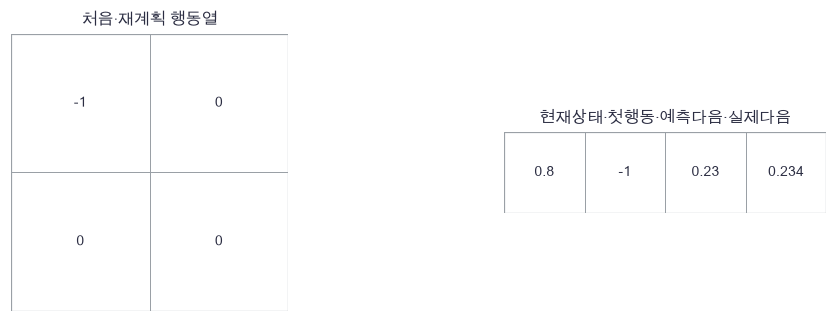

In [35]:
plot_panels([first_plans,replan_table[:1]],['처음·재계획 행동열','현재상태·첫행동·예측다음·실제다음'])

🔍 **확인** · 재계획의 시작점은 실제 관측입니다. 첫 계획의 두 번째 행동을 무조건 실행하지 않습니다. 두 계획이 우연히 같아도 실행 규칙은 다릅니다.

In [36]:
def evaluate_mpc(p,kind,horizon,seed=6090,episodes=16,steps=15,candidates=128):
    """매 step 재계획한 첫 행동만 참 환경에 실행합니다. 모델은 갱신하지 않습니다."""
    # 쓰는 것: shooting_action (3절) · true_step (1절)
    assert 1<=horizon<=8, '고정 후보은행의 계획 길이는1–8이어야 합니다'
    start_rng=np.random.default_rng(seed)
    plan_rng=np.random.default_rng(seed+1)
    state=start_rng.uniform(-1.5,1.5,(episodes,1))
    returns=np.zeros(episodes)
    states=[state[:,0].copy()]
    actions=[]
    for time in range(steps):
        proposals=plan_rng.uniform(-1.,1.,(episodes,candidates,8))
        proposals[:,0,:]=0.
        if kind=='zero':
            action=np.zeros_like(state)
        elif kind=='feedback':
            action=np.clip(-1.3*state,-1.,1.)
        else:
            action,_,_,_=shooting_action(state,proposals[:,:,:horizon],p,kind=='oracle')
        state,reward=true_step(state,action)
        returns+=.95**time*reward[:,0]
        states.append(state[:,0].copy())
        actions.append(action[:,0].copy())
    return returns,np.array(states),np.array(actions)

In [37]:
# 쓰는 것: candidate_start (3절) · copy_parameters (2절) · fitted (2절) · shooting_action (3절) · true_step (1절)
before=copy_parameters(fitted)
mini_returns,mini_states,mini_actions=evaluate_mpc(fitted,'learned',4,seed=6080,episodes=2,steps=2,candidates=8)
for key in fitted:
    np.testing.assert_array_equal(fitted[key],before[key])  # 검산: MPC 중 모델 학습 없음
for t in range(2):
    next_s,_=true_step(mini_states[t,:,None],mini_actions[t,:,None])
    np.testing.assert_allclose(next_s[:,0],mini_states[t+1])  # 검산: 실행 경로는 참 환경의 관측
try:
    shooting_action(candidate_start,np.zeros((1,2,0)),fitted)
except AssertionError:
    print('계획 길이0은 의도대로 거부합니다.')
else:
    raise AssertionError('첫 행동 없는 계획은 거부되어야 합니다')
print('MPC의 실제 실행과 고정 모델을 확인했습니다.')

계획 길이0은 의도대로 거부합니다.
MPC의 실제 실행과 고정 모델을 확인했습니다.


### ✏️ 연습 4 · 다음 계획의 시작점

MPC 재계획은 실제 관측의 독립 사본에서 시작하세요.

In [38]:
def exercise_model_rollout(observed_next,predicted_next):
    """MPC 재계획은 실제 관측의 독립 사본에서 시작하세요."""

    ### 구현할 내용: MPC 재계획은 실제 관측의 독립 사본에서 시작하세요.
    raise NotImplementedError
    return start

In [39]:
def check_model_rollout(candidate):
    """작은 독립 기준값과 비교합니다."""
    np.testing.assert_array_equal(candidate(np.array([[.4]]),np.array([[.7]])),[[.4]])  # 검산: 예측.7이 아니라 관측.4
    print("연습 4: 독립 기준값과 일치합니다.")

run_check(check_model_rollout,exercise_model_rollout,hint="MPC 재계획은 실제 관측의 독립 사본에서 시작하세요.")

☐ exercise_model_rollout: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: MPC 재계획은 실제 관측의 독립 사본에서 시작하세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
start = observed_next.copy()
```

</details>

## 🔑 5. 모델 오차와 계획 길이의 효과를 나누어 봅니다

**이 절에서 가져갈 것:** one-step 정확도·open-loop 오차·실제 MPC 반환은 서로 다른 검산입니다.

모델이 한 번은 정확해도 자신의 예측을 다시 입력하면 오차가 누적될 수 있습니다. 긴 계획은 더 먼 보상을 보지만 같은 후보 수로 더 큰 행동열 공간을 탐색해야 합니다.

고정 평가: 독립 시작seed6090,16episode×15step, 할인.95. 후보은행seed6091, 시각마다128후보×최대길이8을 미리 뽑고 H=1/4/8은 같은 은행의 앞부분을 사용합니다. 후보0은 항상 무행동열이며 나머지는uniform[−1,1]입니다. 방법·길이별로 상태는 달라져도 같은 시각에 비교하는 행동열은 같습니다.

a=0·고정feedback `clip(−1.3s)`·oracle MPC H4·학습모델 MPC H1/H4/H8의 실제 반환을 비교합니다. oracle도128후보의 유한길이 계획이므로 최적 정책은 아닙니다. 학습모델의 계획상태나 보상을 참 값으로 바꾸는 fallback은 없습니다. 최종 지표는 실제 참 환경에서 얻은15step 할인 반환의 episode 평균, 조건부 SE, 관측 상태 중 train범위[−1.5,1.5] 밖 비율입니다. 한 학습seed·한 고정후보은행의 교육용 결과입니다.

별도 open-loop 진단(seed6085)은16개 시작상태에서 선택한 길이8 행동열을 고정하고, 학습모델과 정확모델에서 **같은 행동열**을 끝까지 펼칩니다. 시각별 상태 MSE를 계산합니다. 이 값은 재계획하는 MPC 반환과 같지 않습니다. test를 확인한 뒤 H·모델·후보예산을 고르지 않습니다.

In [40]:
planning_budget=np.array([[1.,128.,128.],[4.,128.,512.],[8.,128.,1024.]])
error_types=np.array([[512.,1.],[16.,8.],[16.,15.]])
fixed_action_examples=np.array([[-1.,0.,0.,0.],[0.,0.,0.,0.],[.5,-.5,.5,-.5]])

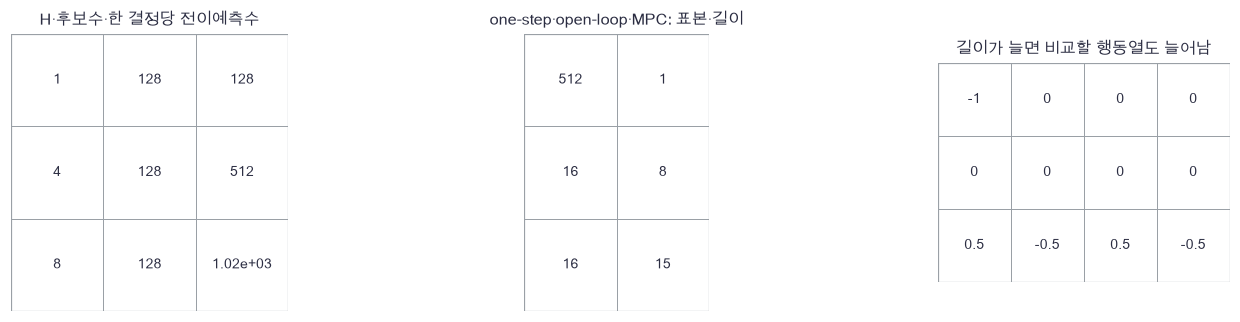

In [41]:
plot_panels([planning_budget,error_types,fixed_action_examples],['H·후보수·한 결정당 전이예측수','one-step·open-loop·MPC: 표본·길이','길이가 늘면 비교할 행동열도 늘어남'])

🔍 **확인** · H8은 한 결정마다1024개 모델 전이를 예측합니다. 계획이 길수록 계산과 탐색 난도도 바뀌므로 H효과만 단순한 성능 우위로 읽지 않습니다.

In [42]:
# 쓰는 것: fitted (2절) · rollout_sequences (3절) · shooting_action (3절)
diagnostic_rng=np.random.default_rng(6085)
diagnostic_start=diagnostic_rng.uniform(-1.5,1.5,(16,1))
diagnostic_proposals=diagnostic_rng.uniform(-1,1,(16,128,8))
diagnostic_proposals[:,0,:]=0.
_,selected_sequences,_,_=shooting_action(diagnostic_start,diagnostic_proposals,fitted)
_,model_paths=rollout_sequences(diagnostic_start,selected_sequences[:,None,:],fitted)
_,true_paths=rollout_sequences(diagnostic_start,selected_sequences[:,None,:],None,True)
step_mse=((model_paths[:,0]-true_paths[:,0])**2).mean(axis=0)
error_curve=np.column_stack([np.arange(9),step_mse])
print('같은 고정 행동열의 시각별 상태 MSE',np.round(step_mse,5))
_,all_candidate_paths=rollout_sequences(diagnostic_start,diagnostic_proposals,fitted)
planned_outside=np.mean(np.abs(all_candidate_paths)>1.5)
print("계획 후보의 예측 상태 중 학습 범위 밖 비율",planned_outside)

같은 고정 행동열의 시각별 상태 MSE [0.      0.00024 0.00025 0.00031 0.00047 0.00079 0.00119 0.00185 0.00276]
계획 후보의 예측 상태 중 학습 범위 밖 비율 0.004231770833333333


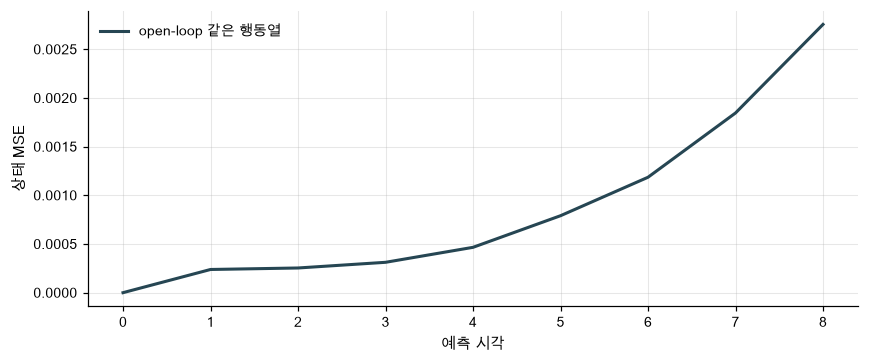

In [43]:
plot_curves([error_curve],['open-loop 같은 행동열'],'상태 MSE',xlabel='예측 시각')

In [44]:
# 쓰는 것: evaluate_mpc (4절) · fitted (2절)
settings=[('행동0','zero',1),('고정 feedback','feedback',1),('oracle H4','oracle',4),
          ('학습 H1','learned',1),('학습 H4','learned',4),('학습 H8','learned',8)]
results=[]
traces=[]
start=perf_counter()
for label,kind,horizon in settings:
    returns,states,actions=evaluate_mpc(fitted,kind,horizon)
    outside=np.mean(np.abs(states)>1.5)
    results.append([returns.mean(),returns.std(ddof=1)/np.sqrt(len(returns)),outside])
    traces.append(states[:,0])
results=np.array(results)
print('고정 평가 전체 실행 초',round(perf_counter()-start,2))
for setting,row in zip(settings,results):
    print(setting[0],np.round(row,5))
assert np.isfinite(results).all(), '모든 실제 평가값은 유한해야 합니다'

고정 평가 전체 실행 초 0.05
행동0 [-3.75944  0.37091  0.     ]
고정 feedback [-0.19118  0.0458   0.     ]
oracle H4 [-0.25511  0.0542   0.     ]
학습 H1 [-0.19622  0.04585  0.     ]
학습 H4 [-0.30916  0.04991  0.     ]
학습 H8 [-0.43815  0.06678  0.     ]


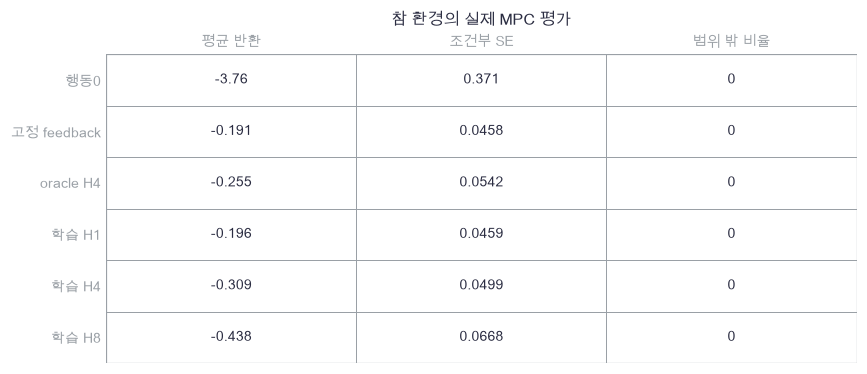

In [45]:
plot_panels([results],['참 환경의 실제 MPC 평가'],[['평균 반환','조건부 SE','범위 밖 비율']],rows=[[s[0] for s in settings]])

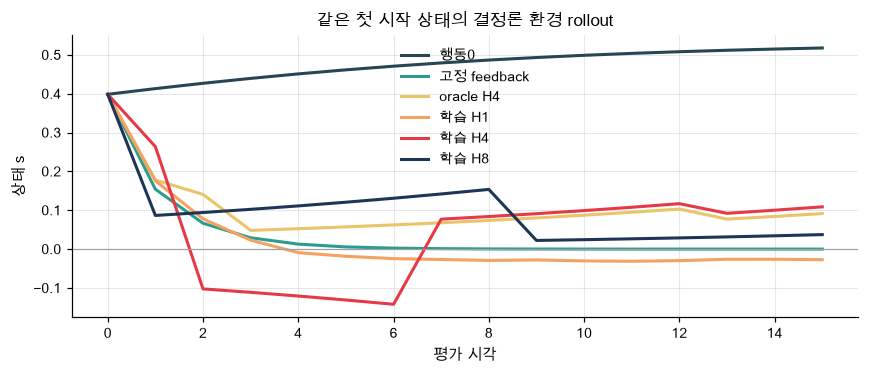

In [46]:
plot_trajectories(np.arange(16),traces,[s[0] for s in settings])

🔍 **확인** · 표의 반환은 실제 실행에서 얻은 값입니다. oracle과 학습모델의 차이는 모델오차뿐 아니라 그 오차로 바뀐 후보 선택·후속 상태도 포함합니다. H를 늘렸을 때 더 나빠져도 모델오차와 고정 후보 탐색 한계가 함께 작용할 수 있습니다. 새로운 H를 고르려면 별도의 validation 계획과 새 test를 마련해야 합니다. 계획 후보의 예측 상태가 |s|>1.5이면 학습 상태 범위 밖의 외삽입니다. 모든 후보·시각의 계획상 외삽 비율과 실제 실행 상태의 범위 밖 비율을 따로 계산했습니다. 실제 실행이 범위 안에 머물러도 후보 평가에서는 범위 밖 모델값을 쓸 수 있습니다. 이 고정 실행에서는 학습 H1/H4/H8 반환이 약−.196/−.309/−.438이며 긴 계획이 더 좋지 않았습니다. 모델 오차와 같은128후보의 탐색 한계를 함께 고려해야 합니다.

### ✏️ 연습 5 · 계획 계산 예산

MPC에서 모델이 예측하는 총 scalar 전이 수를 계산하세요. vectorized 호출 횟수와 다릅니다.

In [47]:
def exercise_planning_cost(episodes,candidates,horizon,steps):
    """MPC에서 모델이 예측하는 총 scalar 전이 수를 계산하세요. vectorized 호출 횟수와 다릅니다."""

    ### 구현할 내용: MPC에서 모델이 예측하는 총 scalar 전이 수를 계산하세요. vectorized 호출 횟수와 다릅니다.
    raise NotImplementedError
    return calls

In [48]:
def check_planning_cost(candidate):
    """작은 독립 기준값과 비교합니다."""
    np.testing.assert_equal(candidate(16,128,4,15),122880)  # 검산:16×128×4×15
    print("연습 5: 독립 기준값과 일치합니다.")

run_check(check_planning_cost,exercise_planning_cost,hint="MPC에서 모델이 예측하는 총 scalar 전이 수를 계산하세요. vectorized 호출 횟수와 다릅니다.")

☐ exercise_planning_cost: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: MPC에서 모델이 예측하는 총 scalar 전이 수를 계산하세요. vectorized 호출 횟수와 다릅니다.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
calls = episodes*candidates*horizon*steps
```

</details>

## ✏️ 끝 연습 · 후보·축·평가 범위를 바꿉니다

### ✏️ 연습 A · 후보별 할인 반환

rewards:(N,K,H)의 시간축만 할인합하세요.

In [49]:
def exercise_rollout_sum(rewards,gamma):
    """rewards:(N,K,H)의 시간축만 할인합하세요."""
    discount = gamma**np.arange(rewards.shape[-1])
    ### 구현할 내용: rewards:(N,K,H)의 시간축만 할인합하세요.
    raise NotImplementedError
    return scores

In [50]:
def check_rollout_sum(candidate):
    """작은 독립 기준값과 비교합니다."""
    np.testing.assert_allclose(candidate(np.array([[[1.,2.],[3.,4.]]]),.5),[[2.,5.]])  # 검산: 후보별1+1,3+2
    print("연습 A: 독립 기준값과 일치합니다.")

run_check(check_rollout_sum,exercise_rollout_sum,hint="rewards:(N,K,H)의 시간축만 할인합하세요.")

☐ exercise_rollout_sum: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: rewards:(N,K,H)의 시간축만 할인합하세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
scores = (rewards*discount).sum(axis=-1)
```

</details>

### ✏️ 연습 B · 다음 상태·보상 오차 분리

두 출력 좌표를 합치지 않고 각각 MSE를 반환하세요.

In [51]:
def exercise_coordinate_mse(prediction,target):
    """두 출력 좌표를 합치지 않고 각각 MSE를 반환하세요."""

    ### 구현할 내용: 두 출력 좌표를 합치지 않고 각각 MSE를 반환하세요.
    raise NotImplementedError
    return mse

In [52]:
def check_coordinate_mse(candidate):
    """작은 독립 기준값과 비교합니다."""
    np.testing.assert_allclose(candidate(np.array([[1.,2.],[3.,4.]]),np.zeros((2,2))),[5.,10.])  # 검산: 좌표별 제곱 평균
    print("연습 B: 독립 기준값과 일치합니다.")

run_check(check_coordinate_mse,exercise_coordinate_mse,hint="두 출력 좌표를 합치지 않고 각각 MSE를 반환하세요.")

☐ exercise_coordinate_mse: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: 두 출력 좌표를 합치지 않고 각각 MSE를 반환하세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
mse = ((prediction-target)**2).mean(axis=0)
```

</details>

### ✏️ 연습 C · 계획에서 실행할 행동

MPC 계획열 (N,H)에서 실제 실행할 첫 행동 (N,1)을 고르세요.

In [53]:
def exercise_first_only(planned):
    """MPC 계획열 (N,H)에서 실제 실행할 첫 행동 (N,1)을 고르세요."""

    ### 구현할 내용: MPC 계획열 (N,H)에서 실제 실행할 첫 행동 (N,1)을 고르세요.
    raise NotImplementedError
    return action

In [54]:
def check_first_only(candidate):
    """작은 독립 기준값과 비교합니다."""
    np.testing.assert_array_equal(candidate(np.array([[1.,2.,3.],[-1.,0.,1.]])),[[1.],[-1.]])  # 검산: 각 상태의 첫 행동만
    print("연습 C: 독립 기준값과 일치합니다.")

run_check(check_first_only,exercise_first_only,hint="MPC 계획열 (N,H)에서 실제 실행할 첫 행동 (N,1)을 고르세요.")

☐ exercise_first_only: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: MPC 계획열 (N,H)에서 실제 실행할 첫 행동 (N,1)을 고르세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
action = planned[:,:1]
```

</details>

### ✏️ 연습 D · 학습 상태 범위 밖의 비율

경계는 포함하고 학습 범위 바깥의 관측 비율을 구하세요.

In [55]:
def exercise_extrapolation(states,low,high):
    """경계는 포함하고 학습 범위 바깥의 관측 비율을 구하세요."""

    ### 구현할 내용: 경계는 포함하고 학습 범위 바깥의 관측 비율을 구하세요.
    raise NotImplementedError
    return fraction

In [56]:
def check_extrapolation(candidate):
    """작은 독립 기준값과 비교합니다."""
    np.testing.assert_allclose(candidate(np.array([-2.,-1.,0.,1.,2.]),-1.,1.),.4)  # 검산: 다섯 상태 중 바깥 둘
    print("연습 D: 독립 기준값과 일치합니다.")

run_check(check_extrapolation,exercise_extrapolation,hint="경계는 포함하고 학습 범위 바깥의 관측 비율을 구하세요.")

☐ exercise_extrapolation: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: 경계는 포함하고 학습 범위 바깥의 관측 비율을 구하세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
fraction = np.mean((states<low)|(states>high))
```

</details>

### ✏️ 준비도 질문

- **설명:** 모델 학습과 shooting 계획은 무엇이 다르며 MPC는 언제 실제 관측으로 돌아오나요? → 1–4절
- **수식:** 두 출력 모델의 손실 분모·미분과 후보별 할인합을 쓸 수 있나요? → 2·3절
- **구현:** 모든 모델 배열·입력의 미분, 후보 반복문·벡터화, 첫 행동 실행과 모델 동결을 검산할 수 있나요? → 2–4절
- **변형 검산:** H·후보수·분포 밖 상태가 바뀌면 one-step·open-loop·closed-loop 지표를 어떻게 나누나요? → 5절, 연습 A–D

### 📎 원전과 다음 연결

[Neural Network Dynamics for Model-Based Deep RL, Nagabandi et al.](https://arxiv.org/abs/1708.02596)은 학습한 신경망 전이 모델과 MPC의 연결을 보여 줍니다. 여기서는 관측의 전이·보상 모두를 작은 MLP로 학습하고 고정 shooting 후보로 계획합니다. 원논문의 로봇 benchmark나 model-free fine-tuning을 재현한 것은 아닙니다. 61번에서는 새 전이를 수집하지 못하는 고정 데이터 조건에서 coverage·Q 외삽·정책 평가를 확인합니다.